# Ejercicio de programación - Regresión Logística

En este cuaderno se implementa **regresión logística desde cero** y se aplica al conjunto de datos de aprobación de préstamos `Loan_approval_data_2025.csv`. La variable objetivo es `loan_status`, que vale `1` si el préstamo fue aprobado y `0` si fue rechazado.

El desarrollo sigue la estructura de los cuadernos `01_reg_log_01.ipynb` y `02_reg_log_02.ipynb`:

1. Carga y preparación de los datos.
2. División en entrenamiento y prueba.
3. Visualización exploratoria.
4. Implementación de la función sigmoidea, la función de costo y el gradiente.
5. Entrenamiento con descenso por gradiente y con `scipy.optimize`.
6. Evaluación del modelo sobre el conjunto de prueba.


## Acerca del conjunto de datos

El archivo `descripciondataset.txt` describe el dataset de la siguiente manera:

> **Conjunto de datos sintéticos de aprobación de préstamos**
>
> Un conjunto de datos realista y de alta calidad para la modelización del riesgo crediticio.
>
> **¿Por qué este conjunto de datos?**
>
> La mayoría de los conjuntos de datos de préstamos en Kaggle tienen patrones poco realistas donde:
>
> - las puntuaciones crediticias no importan;
> - la lógica de aprobación está al revés;
> - los modelos aprenden patrones sin sentido.
>
> A diferencia de la mayoría de los conjuntos de datos de préstamos disponibles en línea, este se basa en criterios bancarios reales de instituciones financieras estadounidenses y canadienses. Fruto de tres años de experiencia práctica en el sector financiero, el conjunto de datos incorpora correlaciones realistas y lógica empresarial que reflejan cómo se toman las decisiones de préstamo en la práctica. Esto lo convierte en la herramienta ideal para científicos de datos que buscan desarrollar proyectos que demuestren no solo su capacidad de programación, sino también una comprensión profunda del modelado del riesgo crediticio.

### Variables del dataset

| Columna | Tipo | Descripción |
|---|---|---|
| `customer_id` | Texto | Identificador del cliente. No se usa como predictor. |
| `age` | Numérica | Edad del solicitante. |
| `occupation_status` | Categórica | Situación laboral (`Employed`, `Self-Employed`, `Student`). |
| `years_employed` | Numérica | Años de experiencia laboral. |
| `annual_income` | Numérica | Ingreso anual. |
| `credit_score` | Numérica | Puntaje crediticio. |
| `credit_history_years` | Numérica | Años de historial crediticio. |
| `savings_assets` | Numérica | Ahorros y activos disponibles. |
| `current_debt` | Numérica | Deuda actual. |
| `defaults_on_file` | Binaria | Incumplimientos registrados. |
| `delinquencies_last_2yrs` | Numérica | Morosidades en los últimos 2 años. |
| `derogatory_marks` | Numérica | Marcas derogatorias en el historial. |
| `product_type` | Categórica | Tipo de producto (`Credit Card`, `Personal Loan`, `Line of Credit`). |
| `loan_intent` | Categórica | Destino del préstamo (`Business`, `Education`, etc.). |
| `loan_amount` | Numérica | Monto solicitado. |
| `interest_rate` | Numérica | Tasa de interés. |
| `debt_to_income_ratio` | Numérica | Relación deuda/ingreso. |
| `loan_to_income_ratio` | Numérica | Relación préstamo/ingreso. |
| `payment_to_income_ratio` | Numérica | Relación pago/ingreso. |
| `loan_status` | Binaria | Variable objetivo: `1` aprobado, `0` no aprobado. |

El modelo se entrenará para estimar la probabilidad de que `loan_status = 1` a partir de las demás variables.


In [1]:
# se utiliza para el manejo de rutas y directorios.
import os

# Cálculo científico y vectorial para python
import numpy as np

# Manejo de datos tabulares (lectura del csv, codificación de columnas categóricas)
import pandas as pd

# Librerías para graficar
from matplotlib import pyplot

# Módulo de optimización de scipy
from scipy import optimize

# le dice a matplotlib que incruste gráficos en el cuaderno
%matplotlib inline

# opciones de visualización de pandas
pd.set_option('display.max_columns', None)


## 1. Carga y preparación de los datos

El dataset contiene una columna identificadora (`customer_id`) que no aporta información predictiva, tres columnas categóricas de texto (`occupation_status`, `product_type` y `loan_intent`) y la etiqueta `loan_status`. Antes de entrenar el modelo:

- se descarta `customer_id`;
- las columnas categóricas se convierten a variables binarias (*one-hot encoding*);
- `X` queda como una matriz numérica y `y` como el vector de etiquetas.


In [2]:
# Ruta al archivo csv. Si se sube el archivo directamente a Colab, basta con el nombre.
DATA_PATH = 'Loan_approval_data_2025.csv'
# Si se guarda en Google Drive, ajustar la ruta, por ejemplo:
# DATA_PATH = '/content/drive/MyDrive/Colab Notebooks/machine learning/datasets/Loan_approval_data_2025.csv'

df = pd.read_csv(DATA_PATH)

print('Dimensiones del dataset:', df.shape)
df.head()


Dimensiones del dataset: (50000, 20)


,customer_id,age,occupation_status,years_employed,annual_income,credit_score,credit_history_years,savings_assets,current_debt,defaults_on_file,delinquencies_last_2yrs,derogatory_marks,product_type,loan_intent,loan_amount,interest_rate,debt_to_income_ratio,loan_to_income_ratio,payment_to_income_ratio,loan_status
0,CUST100000,40,Employed,17.2,25579,692,5.3,895,10820,0,0,0,Credit Card,Business,600,17.02,0.423,0.023,0.008,1
1,CUST100001,33,Employed,7.3,43087,627,3.5,169,16550,0,1,0,Personal Loan,Home Improvement,53300,14.10,0.384,1.237,0.412,0
2,CUST100002,42,Student,1.1,20840,689,8.4,17,7852,0,0,0,Credit Card,Debt Consolidation,2100,18.33,0.377,0.101,0.034,1
3,CUST100003,53,Student,0.5,29147,692,9.8,1480,11603,0,1,0,Credit Card,Business,2900,18.74,0.398,0.099,0.033,1
4,CUST100004,32,Employed,12.5,63657,630,7.2,209,12424,0,0,0,Personal Loan,Education,99600,13.92,0.195,1.565,0.522,1


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              50000 non-null  object 
 1   age                      50000 non-null  int64  
 2   occupation_status        50000 non-null  object 
 3   years_employed           50000 non-null  float64
 4   annual_income            50000 non-null  int64  
 5   credit_score             50000 non-null  int64  
 6   credit_history_years     50000 non-null  float64
 7   savings_assets           50000 non-null  int64  
 8   current_debt             50000 non-null  int64  
 9   defaults_on_file         50000 non-null  int64  
 10  delinquencies_last_2yrs  50000 non-null  int64  
 11  derogatory_marks         50000 non-null  int64  
 12  product_type             50000 non-null  object 
 13  loan_intent              50000 non-null  object 
 14  loan_amount           

In [4]:
# Distribución de la variable objetivo
conteo_por_clase = df['loan_status'].value_counts().sort_index()
print(conteo_por_clase)
print('Proporción de préstamos aprobados: {:.2%}'.format(df['loan_status'].mean()))


loan_status
0    22477
1    27523
Name: count, dtype: int64
Proporción de préstamos aprobados: 55.05%


In [5]:
# customer_id es solo un identificador: no aporta información predictiva
df = df.drop(columns=['customer_id'])

# columnas categóricas que deben convertirse a variables numéricas
columnas_categoricas = ['occupation_status', 'product_type', 'loan_intent']

# separa la etiqueta (variable objetivo) del resto de columnas
y = df['loan_status'].to_numpy(dtype=float)
X_df = df.drop(columns=['loan_status'])

# convierte las columnas categóricas en columnas binarias (0/1)
# drop_first=True evita la multicolinealidad perfecta entre las dummies de una misma categoría
X_df = pd.get_dummies(X_df, columns=columnas_categoricas, drop_first=True)

# nombres de las columnas finales, en el mismo orden en que quedan en X
nombres_columnas = X_df.columns.tolist()

# convierte todo a un arreglo numpy de tipo float
X = X_df.to_numpy(dtype=float)

print('Dimensiones de X:', X.shape)
print('Dimensiones de y:', y.shape)
print('Número de variables (sin intercepto):', len(nombres_columnas))
print('Columnas de X:')
for nombre in nombres_columnas:
    print(' -', nombre)


Dimensiones de X: (50000, 24)
Dimensiones de y: (50000,)
Número de variables (sin intercepto): 24
Columnas de X:
 - age
 - years_employed
 - annual_income
 - credit_score
 - credit_history_years
 - savings_assets
 - current_debt
 - defaults_on_file
 - delinquencies_last_2yrs
 - derogatory_marks
 - loan_amount
 - interest_rate
 - debt_to_income_ratio
 - loan_to_income_ratio
 - payment_to_income_ratio
 - occupation_status_Self-Employed
 - occupation_status_Student
 - product_type_Line of Credit
 - product_type_Personal Loan
 - loan_intent_Debt Consolidation
 - loan_intent_Education
 - loan_intent_Home Improvement
 - loan_intent_Medical
 - loan_intent_Personal


### 1.1 División en entrenamiento (80%) y prueba (20%)

Para evaluar el modelo de forma honesta, el 20% de los datos se aparta como conjunto de prueba **antes de cualquier entrenamiento**. Ese 20% no se usa para ajustar `theta` ni para calcular la media y la desviación estándar de la normalización. La división es aleatoria con una semilla fija para que sea reproducible.


In [6]:
np.random.seed(42)

m_total = X.shape[0]
indices = np.random.permutation(m_total)

m_train = int(0.8 * m_total)
train_idx = indices[:m_train]
test_idx = indices[m_train:]

# los índices de entrenamiento y prueba son disjuntos
assert len(np.intersect1d(train_idx, test_idx)) == 0

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

print('Ejemplos totales:', m_total)
print('Ejemplos de entrenamiento (80%):', X_train.shape[0])
print('Ejemplos de prueba (20%):', X_test.shape[0])
print('Proporción de aprobados en entrenamiento: {:.2%}'.format(y_train.mean()))
print('Proporción de aprobados en prueba: {:.2%}'.format(y_test.mean()))


Ejemplos totales: 50000
Ejemplos de entrenamiento (80%): 40000
Ejemplos de prueba (20%): 10000
Proporción de aprobados en entrenamiento: 55.07%
Proporción de aprobados en prueba: 54.95%


### 1.2 Visualización de los datos

Antes de implementar el algoritmo, se explora la distribución de la variable objetivo y la relación entre dos variables numéricas representativas: `credit_score` y `annual_income`.


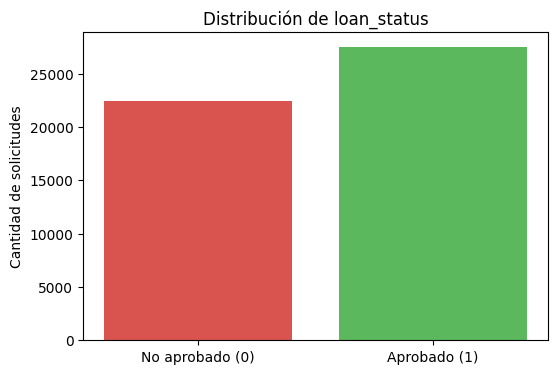

In [7]:
pyplot.figure(figsize=(6, 4))
pyplot.bar(['No aprobado (0)', 'Aprobado (1)'], conteo_por_clase.values, color=['#d9534f', '#5cb85c'])
pyplot.ylabel('Cantidad de solicitudes')
pyplot.title('Distribución de loan_status')
pyplot.show()


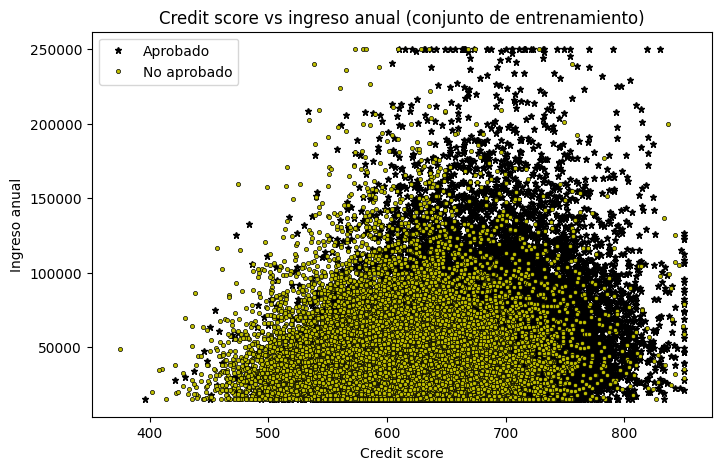

In [8]:
def plotData(X, y, idx_x, idx_y):
    # Grafica los puntos de datos X y y en una nueva figura.
    # Usa '*' para los ejemplos positivos y 'o' para los negativos.
    fig = pyplot.figure(figsize=(8, 5))

    pos = y == 1
    neg = y == 0

    pyplot.plot(X[pos, idx_x], X[pos, idx_y], 'k*', lw=2, ms=5, label='Aprobado')
    pyplot.plot(X[neg, idx_x], X[neg, idx_y], 'ko', mfc='y', ms=3, mec='k', mew=0.5, label='No aprobado')
    pyplot.legend()

idx_credit_score = nombres_columnas.index('credit_score')
idx_annual_income = nombres_columnas.index('annual_income')

plotData(X_train, y_train, idx_credit_score, idx_annual_income)
pyplot.xlabel('Credit score')
pyplot.ylabel('Ingreso anual')
pyplot.title('Credit score vs ingreso anual (conjunto de entrenamiento)')
pyplot.show()


## 2. Implementación de la regresión logística

### 2.1 Función sigmoidea

La hipótesis para la regresión logística se define como:

$$ h_\theta(x) = g(\theta^T x)$$

donde la función $g$ es la función sigmoidea:

$$g(z) = \frac{1}{1+e^{-z}}$$

Para valores positivos grandes de `z`, la sigmoide debe ser cercana a 1; para valores negativos grandes, cercana a 0. Además, `sigmoid(0) = 0.5`. La función debe trabajar con escalares, vectores y matrices.


In [9]:
def sigmoid(z):
    # Calcula la sigmoide de una entrada z
    z = np.asarray(z, dtype=float)
    g = 1 / (1 + np.exp(-z))
    return g


In [10]:
# Prueba de la función sigmoid
z = [-100, 0, 0.5, 100]
g = sigmoid(z)

print('g(', z, ') = ', g)


g( [-100, 0, 0.5, 100] ) =  [3.72007598e-44 5.00000000e-01 6.22459331e-01 1.00000000e+00]


### 2.2 Normalización de características

Las variables tienen escalas muy distintas (por ejemplo, `annual_income` frente a `age`), por lo que se normalizan a media 0 y desviación estándar 1. Para evitar fuga de información (*data leakage*), la media (`mu`) y la desviación estándar (`sigma`) se calculan **solo con el conjunto de entrenamiento** y se reutilizan para normalizar el conjunto de prueba.


In [11]:
def featureNormalize(X, mu=None, sigma=None):
    # Si no se proveen mu y sigma, se calculan a partir de X.
    # Esto se usa SOLO con el conjunto de entrenamiento.
    if mu is None or sigma is None:
        mu = np.mean(X, axis=0)
        sigma = np.std(X, axis=0)

    # evita divisiones por cero si alguna columna es constante
    sigma = np.where(sigma == 0, 1.0, sigma)
    X_norm = (X - mu) / sigma
    return X_norm, mu, sigma


In [12]:
# mu y sigma se calculan SOLO con los datos de entrenamiento
X_train_norm, mu, sigma = featureNormalize(X_train)

# los datos de prueba se normalizan con el mu y sigma del entrenamiento
X_test_norm, _, _ = featureNormalize(X_test, mu, sigma)


### 2.3 Término de intercepción

Se agrega una columna de unos al inicio de `X` para que `theta[0]` represente el término independiente.


In [13]:
m_train, n = X_train_norm.shape
X_train_final = np.concatenate([np.ones((m_train, 1)), X_train_norm], axis=1)

m_test, _ = X_test_norm.shape
X_test_final = np.concatenate([np.ones((m_test, 1)), X_test_norm], axis=1)

print('X_train_final:', X_train_final.shape)
print('X_test_final:', X_test_final.shape)
print('Número de parámetros theta:', X_train_final.shape[1])


X_train_final: (40000, 25)
X_test_final: (10000, 25)
Número de parámetros theta: 25


### 2.4 Función de costo y gradiente

La función de costo de la regresión logística es:

$$ J(\theta) = \frac{1}{m} \sum_{i=1}^{m} \left[ -y^{(i)} \log\left(h_\theta\left( x^{(i)} \right) \right) - \left( 1 - y^{(i)}\right) \log \left( 1 - h_\theta\left( x^{(i)} \right) \right) \right]$$

y el gradiente es:

$$ \frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m} \sum_{i=1}^m \left( h_\theta \left( x^{(i)} \right) - y^{(i)} \right) x_j^{(i)}$$

Aunque el gradiente tiene la misma forma que en la regresión lineal, aquí $h_\theta(x)$ es la función sigmoidea.


In [14]:
def calcularCosto(theta, X, y):
    # Calcula el costo J(theta) para la regresión logística
    m = y.size
    h = sigmoid(X.dot(theta.T))

    # pequeña tolerancia para evitar log(0)
    h = np.clip(h, 1e-12, 1 - 1e-12)

    J = (1 / m) * np.sum(-y.dot(np.log(h)) - (1 - y).dot(np.log(1 - h)))
    return J


In [15]:
def costFunction(theta, X, y):
    # Devuelve el costo y el gradiente para scipy.optimize
    m = y.size
    h = sigmoid(X.dot(theta.T))
    h = np.clip(h, 1e-12, 1 - 1e-12)

    J = (1 / m) * np.sum(-y.dot(np.log(h)) - (1 - y).dot(np.log(1 - h)))
    grad = (1 / m) * (h - y).dot(X)

    return J, grad


In [16]:
# Costo inicial con theta = 0
initial_theta = np.zeros(X_train_final.shape[1])
costo_inicial, grad_inicial = costFunction(initial_theta, X_train_final, y_train)

print('Costo inicial (theta = 0): {:.4f}'.format(costo_inicial))
print('Primeros valores del gradiente inicial:', grad_inicial[:5])


Costo inicial (theta = 0): 0.6931
Primeros valores del gradiente inicial: [-0.0507     -0.15703968 -0.10869982 -0.07887436 -0.24670517]


### 2.5 Entrenamiento con descenso por gradiente


In [17]:
def descensoGradiente(theta, X, y, alpha, num_iters):
    # Inicializa algunos valores
    m = y.shape[0]

    # realiza una copia de theta, el cual será actualizado por el descenso por el gradiente
    theta = theta.copy()
    J_history = []

    for i in range(num_iters):
        h = sigmoid(X.dot(theta.T))
        theta = theta - (alpha / m) * (h - y).dot(X)
        J_history.append(calcularCosto(theta, X, y))

    return theta, J_history


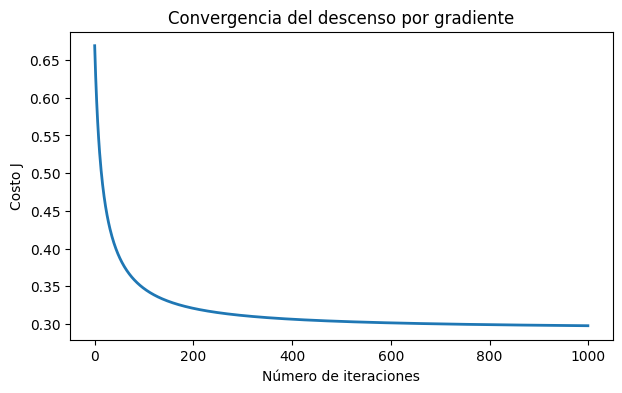

Costo final con descenso por gradiente: 0.2976
Primeros parámetros theta: [0.25232944 0.10308137 0.25333872 0.36792994 1.40601751]


In [18]:
# Elegir algún valor para alpha (probar varias alternativas)
alpha = 0.1
num_iters = 1000

# inicializa theta y ejecuta el descenso por el gradiente
theta_gd = np.zeros(X_train_final.shape[1])
theta_gd, J_history = descensoGradiente(theta_gd, X_train_final, y_train, alpha, num_iters)

# Grafica la convergencia del costo
pyplot.figure(figsize=(7, 4))
pyplot.plot(np.arange(len(J_history)), J_history, lw=2)
pyplot.xlabel('Número de iteraciones')
pyplot.ylabel('Costo J')
pyplot.title('Convergencia del descenso por gradiente')
pyplot.show()

print('Costo final con descenso por gradiente: {:.4f}'.format(J_history[-1]))
print('Primeros parámetros theta:', theta_gd[:5])


### 2.6 Entrenamiento con `scipy.optimize`

El descenso por gradiente requiere elegir una tasa de aprendizaje y un número de iteraciones. Como alternativa, se utiliza `scipy.optimize.minimize`, que encuentra los parámetros óptimos minimizando directamente la función de costo. Se usa `L-BFGS-B` con el gradiente calculado en `costFunction`.


In [19]:
# Establecer las opciones para optimize.minimize
options = {'maxiter': 1000}

res = optimize.minimize(costFunction,
                        initial_theta,
                        (X_train_final, y_train),
                        jac=True,
                        method='L-BFGS-B',
                        options=options)

# la propiedad fun contiene el valor del costo con theta optimizado
costo_opt = res.fun

# theta optimizado está en la propiedad x
theta_opt = res.x

print('¿Optimización exitosa?', res.success)
print('Mensaje:', res.message)
print('Número de iteraciones:', res.nit)
print('Costo con scipy.optimize: {:.4f}'.format(costo_opt))
print('Primeros parámetros theta:', theta_opt[:5])


¿Optimización exitosa? True
Mensaje: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
Número de iteraciones: 68
Costo con scipy.optimize: 0.2906
Primeros parámetros theta: [-0.40372812  0.04099923  0.31729215  0.36507963  0.7687535 ]


## 3. Evaluación del modelo

Se evalúa el modelo sobre el 20% de datos de prueba, que no se usó durante el entrenamiento. La predicción binaria se obtiene con un umbral de 0.5: si la probabilidad estimada es mayor o igual a 0.5, se predice préstamo aprobado (`1`).


In [20]:
def predict(theta, X):
    # Devuelve la predicción binaria (0 o 1) usando un umbral de 0.5
    return (sigmoid(X.dot(theta)) >= 0.5).astype(int)


In [21]:
def evaluarModelo(nombre, theta, X, y):
    prob = sigmoid(X.dot(theta))
    pred = (prob >= 0.5).astype(int)

    exactitud = np.mean(pred == y)

    VP = np.sum((pred == 1) & (y == 1))
    VN = np.sum((pred == 0) & (y == 0))
    FP = np.sum((pred == 1) & (y == 0))
    FN = np.sum((pred == 0) & (y == 1))

    precision = VP / (VP + FP) if (VP + FP) > 0 else 0
    recall = VP / (VP + FN) if (VP + FN) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    print('Modelo:', nombre)
    print('  Exactitud (accuracy): {:.2f}%'.format(exactitud * 100))
    print('  Precisión:            {:.2f}%'.format(precision * 100))
    print('  Recall (sensibilidad):{:.2f}%'.format(recall * 100))
    print('  F1-score:             {:.2f}%'.format(f1 * 100))
    print('  Matriz de confusión:')
    print('                    Predicho 0   Predicho 1')
    print('  Real 0 (no aprob.)   {:8d}     {:8d}'.format(VN, FP))
    print('  Real 1 (aprobado)    {:8d}     {:8d}'.format(FN, VP))
    print()

    return prob, pred

print('Evaluación sobre el conjunto de prueba (20%):\n')
prob_gd, pred_gd = evaluarModelo('Descenso por gradiente', theta_gd, X_test_final, y_test)
prob_opt, pred_opt = evaluarModelo('scipy.optimize (L-BFGS-B)', theta_opt, X_test_final, y_test)


Evaluación sobre el conjunto de prueba (20%):

Modelo: Descenso por gradiente
  Exactitud (accuracy): 86.35%
  Precisión:            86.85%
  Recall (sensibilidad):88.57%
  F1-score:             87.70%
  Matriz de confusión:
                    Predicho 0   Predicho 1
  Real 0 (no aprob.)       3768          737
  Real 1 (aprobado)         628         4867

Modelo: scipy.optimize (L-BFGS-B)
  Exactitud (accuracy): 86.51%
  Precisión:            87.10%
  Recall (sensibilidad):88.57%
  F1-score:             87.83%
  Matriz de confusión:
                    Predicho 0   Predicho 1
  Real 0 (no aprob.)       3784          721
  Real 1 (aprobado)         628         4867



### 3.1 Curva ROC y AUC

La exactitud resume el desempeño en un único umbral. La curva ROC muestra la relación entre la tasa de verdaderos positivos y la tasa de falsos positivos para todos los umbrales posibles. El área bajo la curva (AUC) es una medida global de la capacidad de discriminación del modelo.


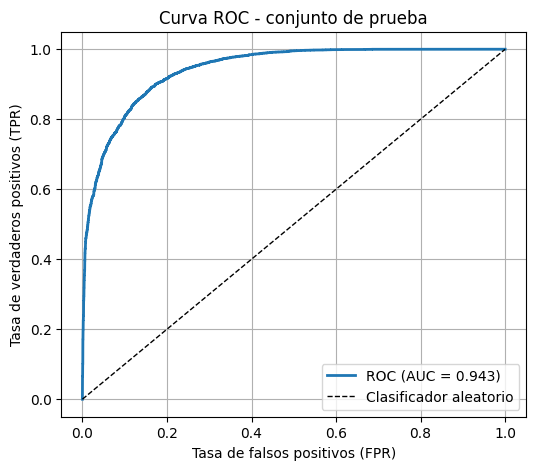

AUC del modelo: 0.9429


In [22]:
def roc_curve_manual(y_true, y_score):
    # Ordena las predicciones de mayor a menor probabilidad
    orden = np.argsort(y_score)[::-1]
    y_true = y_true[orden]

    # Acumula verdaderos positivos y falsos positivos
    tps = np.cumsum(y_true)
    fps = np.cumsum(1 - y_true)

    tpr = tps / tps[-1]
    fpr = fps / fps[-1]

    # Agrega el punto (0, 0) al inicio
    return np.concatenate([[0], fpr]), np.concatenate([[0], tpr])

def auc_manual(fpr, tpr):
    # Área bajo la curva usando la regla del trapecio
    return np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)

fpr, tpr = roc_curve_manual(y_test, prob_opt)
auc = auc_manual(fpr, tpr)

pyplot.figure(figsize=(6, 5))
pyplot.plot(fpr, tpr, lw=2, label='ROC (AUC = {:.3f})'.format(auc))
pyplot.plot([0, 1], [0, 1], 'k--', lw=1, label='Clasificador aleatorio')
pyplot.xlabel('Tasa de falsos positivos (FPR)')
pyplot.ylabel('Tasa de verdaderos positivos (TPR)')
pyplot.title('Curva ROC - conjunto de prueba')
pyplot.legend(loc='lower right')
pyplot.grid(True)
pyplot.show()

print('AUC del modelo: {:.4f}'.format(auc))


### 3.2 Interpretación de los coeficientes

Como las variables numéricas fueron estandarizadas, los coeficientes de `theta` indican el cambio en el log-odds de aprobación asociado a un aumento de una desviación estándar en la variable correspondiente (manteniendo las demás constantes). Los coeficientes positivos aumentan la probabilidad de aprobación y los negativos la reducen.


In [23]:
coeficientes = pd.DataFrame({
    'variable': nombres_columnas,
    'theta': theta_opt[1:]
})
coeficientes['theta_abs'] = coeficientes['theta'].abs()

print('Variables que más aumentan la probabilidad de aprobación:')
print(coeficientes.sort_values('theta', ascending=False).head(10)[['variable', 'theta']].to_string(index=False))

print('\nVariables que más reducen la probabilidad de aprobación:')
print(coeficientes.sort_values('theta', ascending=True).head(10)[['variable', 'theta']].to_string(index=False))


Variables que más aumentan la probabilidad de aprobación:
                    variable    theta
       loan_intent_Education 1.013303
        credit_history_years 0.774706
                credit_score 0.768753
        loan_intent_Personal 0.766670
               annual_income 0.365080
         loan_intent_Medical 0.319181
              years_employed 0.317292
loan_intent_Home Improvement 0.296063
                 loan_amount 0.111971
              savings_assets 0.111633

Variables que más reducen la probabilidad de aprobación:
                   variable     theta
           defaults_on_file -4.373958
product_type_Line of Credit -1.963464
              interest_rate -1.932446
 product_type_Personal Loan -1.771649
       debt_to_income_ratio -1.377749
    delinquencies_last_2yrs -0.752467
           derogatory_marks -0.507350
       loan_to_income_ratio -0.506461
               current_debt -0.475239
    payment_to_income_ratio -0.457057


### 3.3 Ejemplo de predicción individual

Se toma un solicitante del conjunto de prueba y se muestra la probabilidad de aprobación estimada por el modelo, junto con la decisión binaria y el valor real.


In [24]:
i = 0  # primer ejemplo del conjunto de prueba

prob_ejemplo = sigmoid(np.dot(X_test_final[i], theta_opt))
pred_ejemplo = 1 if prob_ejemplo >= 0.5 else 0

print('Probabilidad de aprobación: {:.2%}'.format(prob_ejemplo))
print('Predicción del modelo:', 'Aprobado' if pred_ejemplo == 1 else 'No aprobado')
print('Valor real:', 'Aprobado' if y_test[i] == 1 else 'No aprobado')

print('\nAlgunas características del solicitante:')
for nombre in ['age', 'annual_income', 'credit_score', 'loan_amount', 'debt_to_income_ratio']:
    j = nombres_columnas.index(nombre)
    print('  {}: {:.2f}'.format(nombre, X_test[i, j]))


Probabilidad de aprobación: 92.13%
Predicción del modelo: Aprobado
Valor real: Aprobado

Algunas características del solicitante:
  age: 38.00
  annual_income: 83382.00
  credit_score: 688.00
  loan_amount: 14500.00
  debt_to_income_ratio: 0.14


## 4. Conclusiones

- Se implementó regresión logística desde cero y se aplicó a un problema realista de aprobación de préstamos.
- El dataset requirió codificar variables categóricas y normalizar las variables numéricas; la normalización se ajustó solo con el conjunto de entrenamiento para evitar fuga de información.
- El modelo entrenado con `scipy.optimize` alcanzó una exactitud de **86.51%** sobre el 20% de datos de prueba y un **AUC = 0.943**, lo que indica una buena capacidad de discriminación.
- El descenso por gradiente con `alpha = 0.1` y 1000 iteraciones alcanzó **86.35%** de exactitud, un desempeño muy cercano al óptimo encontrado por `scipy.optimize`.
- Los coeficientes permiten interpretar qué variables aumentan o reducen la probabilidad de aprobación. En un problema crediticio real, también sería importante analizar el impacto ético y regulatorio de las variables utilizadas.

*Nota: los valores exactos de exactitud y AUC pueden variar ligeramente si se cambia la semilla de la división de datos o el preprocesamiento.*
